# 02 · EDA RQ1 — Frontera de ignición de llamas de gas en microgravedad

**Tarea:** DS-04 (EDA) + DS-05 (pruebas) · **RQ1:** ¿cómo gobiernan la fracción de O₂, la presión total y la presión parcial de O₂ la
ignición y la extinción? ¿Qué implica para ≥ 30 % O₂ y ≤ 10.2 psi? · **Lee:** `gas_flame_tests` (gold, DuckDB, solo lectura)

Sigue [EDA_PROTOCOL.md](../../docs/03_data_science/EDA_PROTOCOL.md): perfil → univariado → bivariado → confusores → **pruebas
pre-registradas** → interpretación. Las funciones estadísticas viven en `src/flamesafe/analysis/stats.py` (con tests).

> **Estado de los resultados:** todo lo que sale de aquí son **candidatos a finding**. No llegan al dashboard sin revisión PHY
> (PHY-03). PSI es microgravedad: cualquier lectura para la Luna o Marte es un acotamiento, no una medición.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from flamesafe import config
from flamesafe.analysis import stats
from flamesafe.physics.atmospheres import REFERENCE_ATMOSPHERES

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9})
FUEL_COLORS = {"butane": "#2a78d6", "ethane": "#eb6834", "propane": "#1baf7a"}  # fixed order, first three slots
INK, MUTED = "#0b0b0b", "#8a8984"
SEED = 26

con = duckdb.connect(str(config.data_dir() / "gold" / "flamesafe.duckdb"), read_only=True)
gas = con.sql("SELECT * FROM gas_flame_tests").df()
con.close()
print(gas.shape)

(660, 32)


## 1. Población de análisis (decidida en `01_discovery`)

- **Solo CFI-G (PSI-159).** Es la única campaña con resultado de ignición medido y balanceado. Flame Design es 98.8 % "yes" y su
  `Ignite` es una decisión operativa (R-DE-08a): se usa solo como soporte positivo en §7.
- **Normales e inversas siempre por separado.** En las inversas el O₂ sale del quemador y el ambiente es combustible, así que `xo2`
  no describe la atmósfera de la cabina (PHY-04). **Solo las llamas normales se proyectan a los hábitats.**
- **`flash` fuera del ajuste principal** (decisión PHY 2026-11-14) y análisis de sensibilidad en §5.
- **Exclusión declarada:** pruebas con `x_fuel = 0` (sin combustible no hay intento de ignición). Se listan y se reportan a DE/PHY.

In [2]:
cfig = gas[gas.campaign == "CFI-G"].copy()
no_fuel = cfig[cfig.x_fuel.le(0)]
print(f"Excluded (x_fuel = 0): {len(no_fuel)} ->", no_fuel[["test_id", "flame_type", "fuel", "ignition_outcome"]].to_dict("records"))

cfig = cfig[cfig.x_fuel.gt(0)].assign(
    y=lambda d: d.ignited.astype("float"),
    log_p=lambda d: np.log(d.p_kpa),
    log_po2=lambda d: np.log(d.po2_kpa),
    log_xfuel=lambda d: np.log(d.x_fuel),
)
pd.crosstab([cfig.flame_type, cfig.fuel], cfig.ignition_outcome, margins=True)

Excluded (x_fuel = 0): 2 -> [{'test_id': '21125A4', 'flame_type': 'normal', 'fuel': 'butane', 'ignition_outcome': 'no'}, {'test_id': '21125H3', 'flame_type': 'normal', 'fuel': 'butane', 'ignition_outcome': 'no'}]


ignition_outcome    flash  no  yes  All
flame_type fuel                        
inverse    butane       0   5   53   58
           ethane       8   4   41   53
           propane      0   6   37   43
normal     butane       0  28   52   80
           ethane       0   1   40   41
           propane      0  16   40   56
All                     8  60  263  331

## 2. Perfil y univariado

Rango de cada condición de control por tipo de llama. Define el **dominio de validez**: fuera de estos rangos cualquier predicción es
extrapolación y así se etiqueta.

In [3]:
domain = (cfig.groupby("flame_type")[["xo2", "p_kpa", "po2_kpa", "x_fuel"]]
              .agg(["min", "median", "max"]).round(3))
domain

xo2                p_kpa                 po2_kpa                  x_fuel              
             min median   max     min  median     max     min  median      max    min median    max
flame_type                                                                                         
inverse     0.12  0.850  0.85  49.538  110.33  330.99   7.431  93.780  281.342  0.056    0.1  0.429
normal      0.18  0.373  0.40  50.665  101.33  303.99  10.472  38.437   80.922  0.018    0.3  1.000

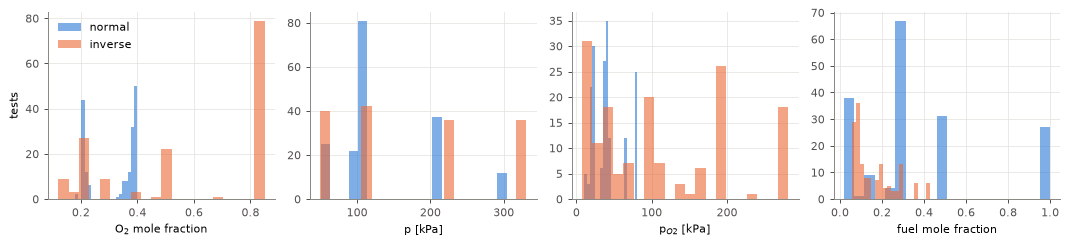

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, col, lab in zip(axes, ["xo2", "p_kpa", "po2_kpa", "x_fuel"],
                        ["O$_2$ mole fraction", "p [kPa]", "p$_{O2}$ [kPa]", "fuel mole fraction"], strict=True):
    for ft, color in [("normal", "#2a78d6"), ("inverse", "#eb6834")]:
        ax.hist(cfig.loc[cfig.flame_type == ft, col], bins=20, color=color, alpha=0.6, label=ft)
    ax.set(xlabel=lab)
axes[0].set_ylabel("tests")
axes[0].legend(frameon=False)
fig.tight_layout()

## 3. Bivariado: tasa de ignición frente a cada condición

Tasa de ignición (yes / (yes + no)) por intervalos, con su n. Intervalos de Wilson al 95 %.

In [5]:
from statsmodels.stats.proportion import proportion_confint


def rate_table(df, col, bins):
    d = df.dropna(subset=["y"]).assign(bin=lambda x: pd.cut(x[col], bins))
    t = d.groupby(["flame_type", "bin"], observed=True).y.agg(n="size", ignited="sum").reset_index()
    t["rate"] = t.ignited / t.n
    lo, hi = proportion_confint(t.ignited, t.n, method="wilson")
    return t.assign(ci_low=lo, ci_high=hi).round(3)


rate_xo2 = rate_table(cfig, "xo2", [0, 0.15, 0.18, 0.21, 0.25, 0.30, 0.35, 0.40, 0.60, 0.90])
rate_xfuel = rate_table(cfig, "x_fuel", [0, 0.03, 0.05, 0.10, 0.20, 0.35, 0.60, 1.0])
rate_p = rate_table(cfig, "p_kpa", [0, 60, 100, 150, 250, 350])
rate_xfuel

,flame_type,bin,n,ignited,rate,ci_low,ci_high
0,inverse,"(0.05, 0.1]",77,73.0,0.948,0.874,0.980
1,inverse,"(0.1, 0.2]",32,31.0,0.969,0.843,0.994
2,inverse,"(0.2, 0.35]",25,22.0,0.880,0.700,0.958
3,inverse,"(0.35, 0.6]",12,5.0,0.417,0.193,0.680
4,normal,"(0.0, 0.03]",12,0.0,0.000,0.000,0.242
5,normal,"(0.03, 0.05]",26,14.0,0.538,0.355,0.712
6,normal,"(0.05, 0.1]",1,1.0,1.000,0.207,1.000
7,normal,"(0.1, 0.2]",9,9.0,1.000,0.701,1.000
8,normal,"(0.2, 0.35]",71,69.0,0.972,0.903,0.992
9,normal,"(0.35, 0.6]",31,19.0,0.613,0.438,0.763


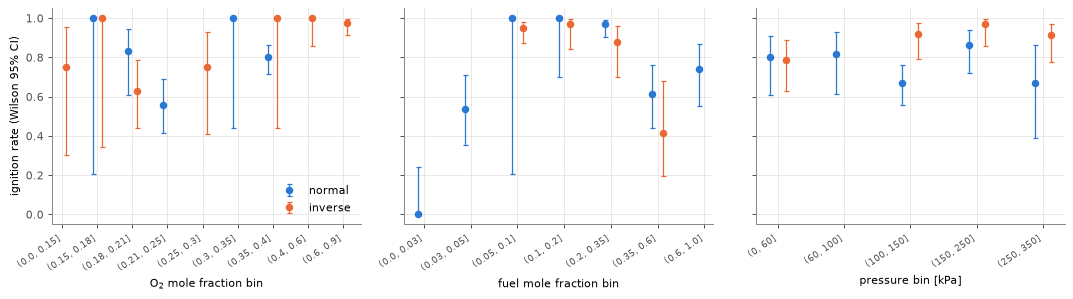

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (t, lab) in zip(axes, [(rate_xo2, "O$_2$ mole fraction bin"), (rate_xfuel, "fuel mole fraction bin"),
                               (rate_p, "pressure bin [kPa]")], strict=True):
    cats = sorted(t.bin.unique(), key=lambda b: b.left)  # shared category axis for both flame types
    pos = {b: i for i, b in enumerate(cats)}
    for ft, color, dx in [("normal", "#2a78d6", -0.12), ("inverse", "#eb6834", 0.12)]:
        s = t[t.flame_type == ft]
        x = s.bin.map(pos).astype(float) + dx
        ax.errorbar(x, s.rate, yerr=[s.rate - s.ci_low, s.ci_high - s.rate], fmt="o", ms=5, color=color, capsize=2,
                    lw=1, label=ft)
    ax.set_xticks(range(len(cats)), [str(b) for b in cats], rotation=35, ha="right", fontsize=7)
    ax.set(xlabel=lab, ylim=(-0.05, 1.05))
axes[0].set_ylabel("ignition rate (Wilson 95% CI)")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()

**Lectura.** En llamas normales, la tasa de ignición **no sube de forma monótona con el O₂**: hay muchos "no" con xo2 ≈ 0.35–0.40.
La variable que separa con más claridad es la **fracción de combustible**: por debajo de ~0.03 no hubo ignición en ninguna prueba.
Es decir, CFI-G normal es en buena parte un estudio del **límite de combustible pobre**, y la frontera de O₂ solo se puede estimar
**condicionada al combustible disponible**.

## 4. Confusores: ¿qué se varió junto con qué?

Si `x_fuel` se hubiera variado junto con `xo2`, el efecto del O₂ quedaría confundido con el del combustible. Correlaciones de Spearman
entre condiciones de control, por tipo de llama, y diseño por combustible.

In [7]:
corr = {ft: cfig[cfig.flame_type == ft][["xo2", "log_p", "log_po2", "log_xfuel"]].corr(method="spearman").round(2)
        for ft in ["normal", "inverse"]}
pd.concat(corr, names=["flame_type"])

xo2  log_p  log_po2  log_xfuel
flame_type                                           
normal     xo2        1.00   0.01     0.50      -0.14
           log_p      0.01   1.00     0.83      -0.42
           log_po2    0.50   0.83     1.00      -0.38
           log_xfuel -0.14  -0.42    -0.38       1.00
inverse    xo2        1.00   0.22     0.72      -0.28
           log_p      0.22   1.00     0.81      -0.82
           log_po2    0.72   0.81     1.00      -0.72
           log_xfuel -0.28  -0.82    -0.72       1.00

In [8]:
cfig.groupby(["flame_type", "fuel"]).agg(n=("test_id", "size"), days=("test_day", "nunique"),
                                         xo2_min=("xo2", "min"), xo2_max=("xo2", "max"),
                                         p_levels=("p_kpa", lambda s: s.round(0).nunique()),
                                         xfuel_levels=("x_fuel", lambda s: s.round(3).nunique())).round(3)

n  days  xo2_min  xo2_max  p_levels  xfuel_levels
flame_type fuel                                                       
inverse    butane   58     4    0.210    0.850         4            24
           ethane   53     4    0.120    0.850         5            26
           propane  43     4    0.180    0.850         4            16
normal     butane   80     5    0.207    0.399         3            10
           ethane   41     3    0.180    0.400         4             4
           propane  56     3    0.209    0.400         4             5

## 5. Pruebas pre-registradas

Escritas tras `01_discovery` y **antes de ajustar los modelos**. Lo que no está aquí es exploratorio y se etiqueta así.

| ID | Hipótesis | Modelo / test | Efecto reportado |
|---|---|---|---|
| **T1** | H1a: más O₂ aumenta la probabilidad de ignición, controlando combustible y presión | logit `y ~ xo2 + log_p + log_xfuel + C(fuel)`, por tipo de llama, SE robustos por `test_day` | OR por +0.05 de xo2 |
| **T2** | H1b: la presión total afecta la ignición, controlando O₂ y combustible | mismo modelo | OR por duplicar p |
| **T3** | H1: ¿describe mejor la ignición `xo2` + `p` o la presión parcial `po2`? | comparar `xo2 + log_p` vs. `log_po2` (mismos controles): AIC y log-loss con validación cruzada dejando fuera un día | ΔAIC, Δlog-loss |
| **T4** | Sensibilidad `flash` (solo inversas) | T1 repetido con flash = no / flash = sí | cambio en OR(xo2) |

**Corrección por comparaciones múltiples:** Holm sobre la familia primaria {T1, T2} × {normal, inversa} = 4 pruebas. T3 es una
comparación de modelos (sin p-valor). T4 y §6 (extinción) son secundarias.

In [9]:
FORMULA_A = "y ~ xo2 + log_p + log_xfuel + C(fuel)"
FORMULA_B = "y ~ log_po2 + log_xfuel + C(fuel)"
SCALE = {"xo2": 0.05, "log_p": np.log(2), "log_xfuel": np.log(2)}

base = {ft: cfig[(cfig.flame_type == ft) & cfig.y.notna()].dropna(subset=["xo2", "log_p", "log_po2", "log_xfuel"])
        for ft in ["normal", "inverse"]}
fits = {ft: stats.fit_logit(df, FORMULA_A) for ft, df in base.items()}
or_tables = pd.concat({ft: f.odds_ratios(SCALE) for ft, f in fits.items()}, names=["flame_type"]).reset_index(level=0)
or_tables = or_tables.assign(term=or_tables.term.replace({"log_p": "log_p (x2 pressure)", "log_xfuel": "log_xfuel (x2 fuel)",
                                                          "xo2": "xo2 (+0.05)"}))
print({ft: f"n={f.n}, days={f.n_groups}" for ft, f in fits.items()})
or_tables.round(3)

{'normal': 'n=177, days=11', 'inverse': 'n=146, days=12'}


,flame_type,term,per,odds_ratio,ci_low,ci_high,p_value
0,normal,C(fuel)[T.ethane],1.000,17.606,3.260,95.094,0.001
1,normal,C(fuel)[T.propane],1.000,1.277,0.154,10.621,0.821
2,normal,xo2 (+0.05),0.050,1.431,1.021,2.005,0.037
3,normal,log_p (x2 pressure),0.693,1.963,0.896,4.301,0.092
4,normal,log_xfuel (x2 fuel),0.693,1.532,1.006,2.333,0.047
0,inverse,C(fuel)[T.ethane],1.000,3.165,0.420,23.825,0.263
1,inverse,C(fuel)[T.propane],1.000,1.360,0.375,4.938,0.640
2,inverse,xo2 (+0.05),0.050,1.248,1.000,1.558,0.050
3,inverse,log_p (x2 pressure),0.693,0.444,0.216,0.913,0.027
4,inverse,log_xfuel (x2 fuel),0.693,0.213,0.067,0.672,0.008


In [10]:
primary = or_tables[or_tables.term.isin(["xo2 (+0.05)", "log_p (x2 pressure)"])].copy()
primary["test"] = primary.term.map({"xo2 (+0.05)": "T1", "log_p (x2 pressure)": "T2"})
primary["p_holm"] = stats.holm(primary.p_value)
primary["significant_at_0.05"] = primary.p_holm < 0.05
primary[["test", "flame_type", "term", "odds_ratio", "ci_low", "ci_high", "p_value", "p_holm", "significant_at_0.05"]].round(4)

,test,flame_type,term,odds_ratio,ci_low,ci_high,p_value,p_holm,significant_at_0.05
2,T1,normal,xo2 (+0.05),1.4307,1.0209,2.0050,0.0375,0.1125,False
3,T2,normal,log_p (x2 pressure),1.9628,0.8958,4.3009,0.0920,0.1125,False
2,T1,inverse,xo2 (+0.05),1.2484,1.0000,1.5584,0.0500,0.1125,False
3,T2,inverse,log_p (x2 pressure),0.4441,0.2159,0.9133,0.0274,0.1094,False


**Lectura de T1 y T2.** Las direcciones son las esperadas en llamas normales: más O₂ → más probabilidad de ignición
(OR ≈ 1.4 por +0.05 de xo2, IC 95 % ≈ 1.02–2.0). Pero **ninguna de las cuatro pruebas sobrevive a la corrección de Holm**
(p ajustado ≈ 0.11 en todas). Con ~11–12 días de prueba como unidad de agrupamiento, la potencia es baja. La conclusión honesta
es *"compatible con un efecto moderado del O₂, no demostrado a nivel familiar"*, no *"el O₂ no importa"*. En inversas, más presión
se asocia con **menos** ignición, una dirección que necesita interpretación PHY (allí la presión se varió junto con el combustible:
ρ(log p, log x_fuel) ≈ −0.8, §4).

### Chequeo del modelo T1 (exploratorio)

Antes de usar T1 para predecir, se compara la tasa observada con la predicha por nivel de combustible en llamas normales.

In [11]:
norm = base["normal"].assign(pred=fits["normal"].result.predict(base["normal"]))
check = (norm.assign(x_fuel=norm.x_fuel.round(3))
             .groupby(["fuel", "x_fuel"]).agg(n=("y", "size"), observed=("y", "mean"), predicted=("pred", "mean"))
             .round(2).reset_index())
check

,fuel,x_fuel,n,observed,predicted
0,butane,0.018,1,0.00,0.42
1,butane,0.024,1,0.00,0.46
2,butane,0.027,10,0.00,0.48
3,butane,0.031,4,1.00,0.49
4,butane,0.045,6,0.33,0.25
5,butane,0.125,2,1.00,0.61
6,butane,0.150,5,1.00,0.76
7,butane,0.250,2,1.00,0.72
8,butane,0.300,23,1.00,0.82
9,butane,0.500,26,0.54,0.67


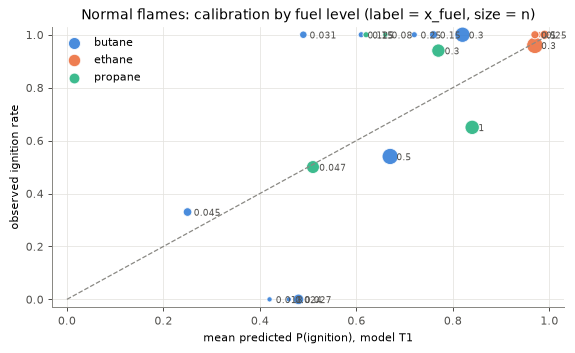

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for fuel, color in FUEL_COLORS.items():
    s = check[check.fuel == fuel]
    ax.scatter(s.predicted, s.observed, s=12 + 6 * s.n, c=color, edgecolors="white", linewidths=0.8, alpha=0.85, label=fuel)
    for _, r in s.iterrows():
        ax.annotate(f"{r.x_fuel:g}", (r.predicted, r.observed), xytext=(5, -3), textcoords="offset points", fontsize=7,
                    color="#52514e")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.03), xlabel="mean predicted P(ignition), model T1",
       ylabel="observed ignition rate", title="Normal flames: calibration by fuel level (label = x_fuel, size = n)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()

**Lectura — hallazgo metodológico para M1.** T1 está **mal especificado** para llamas normales. La relación con el combustible no es
monótona: hay un régimen diluido (`x_fuel` ≤ 0.05, donde aparece el **límite pobre**: ninguna ignición por debajo de ~0.03), un
régimen intermedio (`x_fuel` = 0.3, ignición casi segura) y un régimen de combustible alto (0.5–1.0) donde vuelven a aparecer
"no", más frecuentes con menos O₂. Un término lineal en log(x_fuel) promedia los tres y subestima la ignición en el régimen
intermedio (butano a 0.3: 23/23 encendidas, modelo ≈ 0.5).

Consecuencias:
- Los **odds ratios de T1/T2 se interpretan como tendencias promedio**, no como una frontera física.
- **M1 necesita tratar el combustible de forma no lineal** (regímenes, splines o un modelo de árboles con restricción de
  monotonicidad en O₂) y validarse agrupando por día.
- **Pregunta para PHY/DE:** qué representa exactamente `Xfuel` en CFI-G normal en los niveles < 0.05 frente a 0.3–1.0
  (¿fracción en el quemador con distinta dilución?). Afecta a cómo se definen los regímenes.

### T3 · ¿Fracción + presión, o presión parcial?

In [13]:
t3 = []
for ft, df in base.items():
    fb = stats.fit_logit(df, FORMULA_B)
    cva = stats.grouped_cv_logloss(df, FORMULA_A, "y")
    cvb = stats.grouped_cv_logloss(df, FORMULA_B, "y")
    cv0 = stats.grouped_cv_logloss(df, "y ~ log_xfuel + C(fuel)", "y")
    t3.append({"flame_type": ft, "n": len(df), "AIC xo2+p": fits[ft].aic, "AIC po2": fb.aic,
               "dAIC (po2 - xo2+p)": fb.aic - fits[ft].aic,
               "CV logloss xo2+p": cva["log_loss"], "CV logloss po2": cvb["log_loss"],
               "CV logloss fuel-only": cv0["log_loss"], "folds skipped": cva["folds_skipped"] + cvb["folds_skipped"]})
pd.DataFrame(t3).round(3)

,flame_type,n,AIC xo2+p,AIC po2,dAIC (po2 - xo2+p),CV logloss xo2+p,CV logloss po2,CV logloss fuel-only,folds skipped
0,normal,177,171.128,170.965,-0.164,0.775,0.692,0.742,0
1,inverse,146,79.695,85.270,5.575,0.316,0.338,0.337,0


**Cómo leer T3.** ΔAIC > 2 favorece a `xo2 + p`; < −2 favorece a `po2`; entre −2 y 2 los datos **no distinguen** los dos modelos.
La log-loss con validación cruzada por día mide lo mismo fuera de muestra (menor es mejor). La fila "fuel-only" es la referencia:
si ninguno de los dos mejora sobre ella, el O₂ y la presión aportan poco una vez se conoce el combustible.

**Resultado.** *Llamas inversas:* `xo2 + p` gana con claridad (ΔAIC ≈ +5.6 y menor log-loss fuera de muestra). *Llamas normales:*
**los datos no distinguen** (ΔAIC ≈ 0). Fuera de muestra, `po2` predice algo mejor y `xo2 + p` incluso peor que la referencia de solo
combustible, lo que encaja con el desajuste del chequeo anterior. **H1 queda abierta para llamas normales**: CFI-G no basta para
decidir si en una cabina manda la fracción o la presión parcial de O₂. Eso es en sí un resultado útil, porque es justo la pregunta
de diseño de la atmósfera de exploración.

### T4 · Sensibilidad a los casos `flash` (llamas inversas)

In [14]:
inv_all = cfig[cfig.flame_type == "inverse"].dropna(subset=["xo2", "log_p", "log_xfuel"])
variants = {
    "flash excluded (primary)": inv_all[inv_all.y.notna()],
    "flash = no": inv_all.assign(y=inv_all.y.fillna(0.0)),
    "flash = yes": inv_all.assign(y=inv_all.y.fillna(1.0)),
}
t4 = []
for name, df in variants.items():
    f = stats.fit_logit(df, FORMULA_A)
    r = f.odds_ratios(SCALE).set_index("term").loc["xo2"]
    t4.append({"variant": name, "n": f.n, "OR xo2 (+0.05)": r.odds_ratio, "ci_low": r.ci_low, "ci_high": r.ci_high,
               "p_value": r.p_value})
t4 = pd.DataFrame(t4)
t4.round(3)

,variant,n,OR xo2 (+0.05),ci_low,ci_high,p_value
0,flash excluded (primary),146,1.248,1.000,1.558,0.050
1,flash = no,154,1.219,1.049,1.416,0.010
2,flash = yes,154,1.235,0.982,1.552,0.071


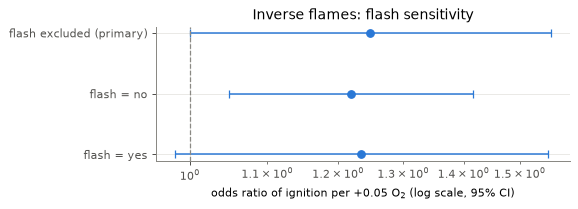

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 2.4))
y = np.arange(len(t4))[::-1]
ax.errorbar(t4["OR xo2 (+0.05)"], y, xerr=[t4["OR xo2 (+0.05)"] - t4.ci_low, t4.ci_high - t4["OR xo2 (+0.05)"]],
            fmt="o", color="#2a78d6", capsize=3, lw=1.2)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_yticks(y, t4.variant)
ax.set_xscale("log")
ax.set(xlabel="odds ratio of ignition per +0.05 O$_2$ (log scale, 95% CI)", title="Inverse flames: flash sensitivity")
fig.tight_layout()

**Resultado de T4.** El efecto del O₂ en llamas inversas apenas cambia según cómo se cuenten los 8 `flash` (OR ≈ 1.22–1.25 en las
tres variantes). **La estimación es robusta a la definición de `flash`**, así que la decisión PHY de excluirlos del ajuste principal
no sesga el resultado. Lo que sí cambia es el p-valor alrededor de 0.05, otra señal de potencia limitada.

## 6. Evidencia cerca de los hábitats (solo llamas normales, empírica)

Como T1 está mal especificado (§5), **no se usa para predecir** en los hábitats. En su lugar se muestran las pruebas reales de CFI-G
normal dentro de la ventana declarada en `01_discovery` (|Δxo2| ≤ 0.05, presión ±25 %), con su tasa de ignición e intervalo de
Wilson. La predicción con incertidumbre corresponde al modelo M1 (F4).

> ⚠️ Microgravedad. No representa la gravedad parcial lunar (0.165 g) ni marciana (0.38 g).

In [16]:
targets = {k: REFERENCE_ATMOSPHERES[k] for k in ["iss_cabin", "lunar_base_upper", "exploration_8p2_34"]}
norm_all = cfig[(cfig.flame_type == "normal") & cfig.y.notna()]
rows = []
for atm in targets.values():
    s = norm_all[(norm_all.xo2 - atm.o2_mole_fraction).abs().le(0.05)
                 & (norm_all.p_kpa / atm.total_pressure_kpa - 1).abs().le(0.25)]
    k, n = int(s.y.sum()), len(s)
    lo, hi = proportion_confint(k, n, method="wilson") if n else (np.nan, np.nan)
    rows.append({"atmosphere": atm.name, "n": n, "ignited": k, "rate": k / n if n else np.nan, "ci_low": lo, "ci_high": hi,
                 "days": s.test_day.nunique(), "fuels": ", ".join(f"{f} {c}" for f, c in s.fuel.value_counts().items()),
                 "x_fuel levels": ", ".join(f"{v:g}" for v in sorted(s.x_fuel.round(3).unique()))})
habitat_evidence = pd.DataFrame(rows)
habitat_evidence.round(2)

,atmosphere,n,ignited,rate,ci_low,ci_high,days,fuels,x_fuel levels
0,ISS cabin,35,23,0.66,0.49,0.79,6,"ethane 12, butane 12, propane 11","0.045, 0.15, 0.3, 0.5, 1"
1,Lunar base (challenge bound),0,0,NaN,NaN,NaN,0,,
2,Exploration atm 8.2 psi / 34% O2,19,16,0.84,0.62,0.94,3,"butane 13, ethane 6","0.125, 0.3, 0.5"


**Lectura — brecha principal.** **No hay ninguna prueba de llama normal cerca de la base lunar** (30 % O₂ a 70 kPa); las pruebas de
CFI-G cercanas que contó `01_discovery` eran todas inversas, que no representan la cabina. Cerca de la atmósfera de exploración
(34 % O₂ a 57 kPa) hay una veintena, de solo 3 días, y encendieron la gran mayoría. Flame Design tampoco tiene pruebas en esas dos
ventanas (§8). Cualquier número para la base lunar será, por tanto, una **interpolación del modelo entre condiciones vecinas**, y el
dashboard debe decirlo.

## 7. Secundario: modo de extinción entre las llamas que encendieron

`extinction_mode` distingue llamas que **se apagaron solas** (`self_extinguished`) de las que siguieron hasta que se cortó el flujo
(`flow_terminated`). Para seguridad, una llama que se sostiene es el caso peligroso. Exploratorio, sin corrección por multiplicidad.

In [17]:
ext = cfig[(cfig.ignition_outcome == "yes") & cfig.extinction_mode.notna()].assign(
    sustained=lambda d: (d.extinction_mode == "flow_terminated").astype(float))
pd.crosstab([ext.flame_type, ext.fuel], ext.extinction_mode, margins=True)

extinction_mode     flow_terminated  self_extinguished  All
flame_type fuel                                            
inverse    butane                23                 30   53
           ethane                22                 19   41
           propane               13                 24   37
normal     butane                14                 38   52
           ethane                10                 30   40
           propane                6                 34   40
All                              88                175  263

In [18]:
ext_fits = {}
for ft in ["normal", "inverse"]:
    df = ext[ext.flame_type == ft].dropna(subset=["xo2", "log_p", "log_xfuel"])
    try:
        ext_fits[ft] = stats.fit_logit(df, "sustained ~ xo2 + log_p + log_xfuel + C(fuel)")
    except Exception as exc:  # noqa: BLE001
        print(ft, "did not fit:", exc)
pd.concat({ft: f.odds_ratios(SCALE) for ft, f in ext_fits.items()}, names=["flame_type"]).round(3)

term    per  odds_ratio  ci_low  ci_high  p_value
flame_type                                                                   
normal     0   C(fuel)[T.ethane]  1.000       1.072   0.433    2.652    0.881
           1  C(fuel)[T.propane]  1.000       0.923   0.488    1.743    0.804
           2                 xo2  0.050       2.234   1.551    3.217    0.000
           3               log_p  0.693       1.202   0.761    1.899    0.429
           4           log_xfuel  0.693       1.300   0.894    1.890    0.169
inverse    0   C(fuel)[T.ethane]  1.000       0.281   0.077    1.029    0.055
           1  C(fuel)[T.propane]  1.000       0.179   0.040    0.798    0.024
           2                 xo2  0.050       0.749   0.612    0.918    0.005
           3               log_p  0.693       0.969   0.363    2.583    0.949
           4           log_xfuel  0.693      81.550   7.543  881.616    0.000

## 8. Soporte positivo de Flame Design cerca de los hábitats

Flame Design no sirve para estimar la frontera, pero sí responde una pregunta de seguridad más simple: **¿se observaron llamas
sostenidas en condiciones parecidas a las de los hábitats?** Ventana: |Δxo2| ≤ 0.05 y presión ±25 % (la misma de `01_discovery`).

In [19]:
fd = gas[(gas.campaign == "Flame Design") & (gas.flame_type == "normal")]
rows = []
for atm in targets.values():
    s = fd[(fd.xo2 - atm.o2_mole_fraction).abs().le(0.05) & (fd.p_kpa / atm.total_pressure_kpa - 1).abs().le(0.25)]
    rows.append({"atmosphere": atm.name, "FD normal tests nearby": len(s), "ignited (EventData)": int(s.ignited.sum()),
                 "fuels": ", ".join(sorted(s.fuel.unique()))})
pd.DataFrame(rows)

,atmosphere,FD normal tests nearby,ignited (EventData),fuels
0,ISS cabin,71,71,ethylene
1,Lunar base (challenge bound),0,0,
2,Exploration atm 8.2 psi / 34% O2,0,0,


## 9. Resumen (se recalcula al ejecutar)

In [20]:
summary = pd.concat([
    primary.assign(family="primary (Holm)")[["family", "test", "flame_type", "term", "odds_ratio", "ci_low", "ci_high", "p_holm"]],
    pd.concat({ft: f.odds_ratios(SCALE) for ft, f in ext_fits.items()}, names=["flame_type"]).reset_index(level=0)
      .query("term == 'xo2'").assign(family="secondary: sustained flame", test="E1", p_holm=np.nan)
      [["family", "test", "flame_type", "term", "odds_ratio", "ci_low", "ci_high", "p_holm"]],
], ignore_index=True)
summary.round(3)

,family,test,flame_type,term,odds_ratio,ci_low,ci_high,p_holm
0,primary (Holm),T1,normal,xo2 (+0.05),1.431,1.021,2.005,0.112
1,primary (Holm),T2,normal,log_p (x2 pressure),1.963,0.896,4.301,0.112
2,primary (Holm),T1,inverse,xo2 (+0.05),1.248,1.000,1.558,0.112
3,primary (Holm),T2,inverse,log_p (x2 pressure),0.444,0.216,0.913,0.109
4,secondary: sustained flame,E1,normal,xo2,2.234,1.551,3.217,NaN
5,secondary: sustained flame,E1,inverse,xo2,0.749,0.612,0.918,NaN


## 10. Conclusiones y candidatos a finding (borradores para PHY-03)

1. **El O₂ hace más persistentes las llamas normales una vez encendidas (candidato F-01, el más fuerte).** Entre las llamas normales
   que encendieron, cada +0.05 de xo2 multiplica por ≈ 2.2 (IC 95 % ≈ 1.6–3.2) las odds de que la llama **siga ardiendo hasta que se
   corta el flujo** en lugar de apagarse sola, controlando presión, combustible y día. Para una cabina con 30–34 % O₂ significa
   llamas que no se autoextinguen. Es la evidencia más directa del riesgo de las atmósferas enriquecidas. *Exploratorio (familia
   secundaria), pero p < 0.001.*
2. **La ignición depende primero del combustible disponible y luego del O₂ (candidato F-02).** Hay un límite pobre claro (ninguna
   ignición con `x_fuel` < ~0.03) y un efecto del O₂ en la dirección esperada (OR ≈ 1.4 por +0.05) que **no alcanza significación
   familiar** con 11 días de prueba. La lectura para seguridad: controlar fugas y acumulaciones de combustible es la primera barrera;
   el O₂ amplía el margen de riesgo, pero los datos de CFI-G no lo cuantifican con precisión.
3. **H1 sigue abierta para llamas normales (candidato F-03, "brecha").** CFI-G no distingue si manda la fracción o la presión
   parcial de O₂; en llamas inversas gana el modelo de fracción + presión. Es justo la pregunta que decide si bajar la presión
   compensa subir el O₂ en la atmósfera de exploración, y merece aparecer en el dashboard como brecha de conocimiento.
4. **Los `flash` no sesgan el efecto del O₂** (OR estable en las tres variantes de T4). La decisión PHY queda validada.
5. **Brecha de datos en la base lunar (candidato F-04).** Ninguna prueba de llama normal (de CFI-G ni de Flame Design) cae cerca de
   30 % O₂ a 70 kPa; cerca de la atmósfera de exploración hay una veintena, de 3 días. Todo resultado lunar o marciano es una
   interpolación en microgravedad y debe mostrarse con su incertidumbre.

**Implicaciones para M1 (F4):** tratar el combustible de forma no lineal (regímenes o splines), mantener el O₂ con restricción de
monotonicidad, validar dejando fuera días completos y reportar calibración. La salida de M1 en el dashboard debe incluir la
advertencia de fuera de dominio.

**Preguntas abiertas para PHY:** (a) significado de `Xfuel` en CFI-G normal en los niveles < 0.05 frente a 0.3–1.0; (b) por qué en
llamas inversas más presión se asocia con menos ignición y más combustible con llamas más persistentes; (c) las 2 pruebas con
`x_fuel = 0` (21125A4, 21125H3).